## Практическое задание №6
#### по дисциплине "Введение в анализ данных"

*Работу выполнил*: Евсеев Григорий, 3826Б1ПМад1

### Часть 2.

Импорт библиотек:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


Загрузка данных, вывод их размеров и структуры:

In [2]:
df = pd.read_excel('02_Автоаварии.xlsx')
print("Размер данных: ", df.shape)

df

Размер данных:  (5000, 37)


,ID,Source,TMC,Severity,Start_Time,End_Time,Distance(mi),Description,Street,Side,...,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight
0,A-1,MapQuest,201.0,3,2016-02-08 05:46:00,2016-02-08 11:00:00,0.01,Right lane blocked due to accident on I-70 Eas...,I-70 E,R,...,False,False,False,False,False,False,False,False,Night,Night
1,A-2,MapQuest,201.0,2,2016-02-08 06:07:59,2016-02-08 06:37:59,0.01,Accident on Brice Rd at Tussing Rd. Expect del...,Brice Rd,L,...,False,False,False,False,False,False,False,False,Night,Night
2,A-3,MapQuest,201.0,2,2016-02-08 06:49:27,2016-02-08 07:19:27,0.01,Accident on OH-32 State Route 32 Westbound at ...,State Route 32,R,...,False,False,False,False,False,False,True,False,Night,Night
3,A-4,MapQuest,201.0,3,2016-02-08 07:23:34,2016-02-08 07:53:34,0.01,Accident on I-75 Southbound at Exits 52 52B US...,I-75 S,R,...,False,False,False,False,False,False,False,False,Night,Day
4,A-5,MapQuest,201.0,2,2016-02-08 07:39:07,2016-02-08 08:09:07,0.01,Accident on McEwen Rd at OH-725 Miamisburg Cen...,Miamisburg Centerville Rd,R,...,False,False,False,False,False,False,True,False,Day,Day
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,A-4996,MapQuest,201.0,2,2016-08-01 11:35:41,2016-08-01 12:05:41,0.00,Accident on Cold Springs Rd at Middletown Rd.,Cold Springs Rd,R,...,False,False,False,False,False,False,False,False,Day,Day
4996,A-4997,MapQuest,201.0,2,2016-08-01 11:41:23,2016-08-01 12:26:23,0.00,Accident on Travis Blvd at Holiday Ln.,Travis Blvd,R,...,False,False,False,False,False,False,True,False,Day,Day
4997,A-4998,MapQuest,201.0,2,2016-08-01 11:57:27,2016-08-01 12:42:27,0.00,Accident on River Rd at Orchard Rd.,River Rd,L,...,False,False,False,False,False,False,False,False,Day,Day
4998,A-4999,MapQuest,201.0,2,2016-08-01 12:00:54,2016-08-01 12:30:54,0.00,Accident on Marconi Ave at Bell St.,Bell St,R,...,False,False,False,False,False,False,False,False,Day,Day


#### Пункт 1а

Выделение отдельно столбцов, нужных для пункта 1а:

In [3]:
cols_1a = ['Severity', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)'] 
data_1a = df[cols_1a].copy()
data_1a

,Severity,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in)
0,3,36.9,NaN,91.0,29.68,10.0,Calm,NaN,0.02
1,2,37.9,NaN,100.0,29.65,10.0,Calm,NaN,0.00
2,2,36.0,33.3,100.0,29.67,10.0,SW,3.5,NaN
3,3,35.1,31.0,96.0,29.64,9.0,SW,4.6,NaN
4,2,36.0,33.3,89.0,29.65,6.0,SW,3.5,NaN
...,...,...,...,...,...,...,...,...,...
4995,2,86.0,NaN,20.0,30.05,10.0,SW,6.9,NaN
4996,2,68.0,NaN,63.0,29.95,10.0,SSW,9.2,NaN
4997,2,68.0,NaN,59.0,29.96,10.0,Variable,3.5,NaN
4998,2,80.6,NaN,34.0,29.94,7.0,South,6.9,NaN


Проверка числа пропущенных значений в этих столбцах:

In [4]:
miss_values = data_1a.isna().sum()
print("Число пропущенных значений:")
print(miss_values[miss_values > 0].to_string())

Число пропущенных значений:
Temperature(F)         22
Wind_Chill(F)        4540
Humidity(%)            22
Pressure(in)           20
Visibility(mi)         42
Wind_Direction         19
Wind_Speed(mph)       459
Precipitation(in)    4808


Можно заметить, что пропущенно много значений признаков `Wind_Chill` и `Precipitation`. Удаление строк с пропущенными значениями привело бы к почти полному опустошению данных. Заменим пропущенные значения в этих двух признаках медианными значениями, при наличии пропусков в строках после замены - удалим строки.

In [5]:
for col in ['Wind_Chill(F)', 'Precipitation(in)']:
    data_1a[col] = data_1a[col].fillna(data_1a[col].median())

data_1a = data_1a.dropna().reset_index(drop = True)
print("Осталось значений после обработки пропусков: ", len(data_1a))
print("Не обработано:", int(data_1a.isna().sum().sum()), " пропусков")
assert int(data_1a.isna().sum().sum()) == 0
data_1a

Осталось значений после обработки пропусков:  4519
Не обработано: 0  пропусков


,Severity,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in)
0,2,36.0,33.3,100.0,29.67,10.0,SW,3.5,0.00
1,3,35.1,31.0,96.0,29.64,9.0,SW,4.6,0.00
2,2,36.0,33.3,89.0,29.65,6.0,SW,3.5,0.00
3,3,37.9,35.5,97.0,29.63,7.0,SSW,3.5,0.03
4,2,34.0,31.0,100.0,29.66,7.0,WSW,3.5,0.00
...,...,...,...,...,...,...,...,...,...
4514,2,86.0,25.2,20.0,30.05,10.0,SW,6.9,0.00
4515,2,68.0,25.2,63.0,29.95,10.0,SSW,9.2,0.00
4516,2,68.0,25.2,59.0,29.96,10.0,Variable,3.5,0.00
4517,2,80.6,25.2,34.0,29.94,7.0,South,6.9,0.00


In [6]:
print(data_1a['Wind_Direction'].value_counts())

Wind_Direction
WNW         742
West        604
South       501
NW          466
SSW         459
SW          349
NNW         298
WSW         219
North       201
Variable    191
SSE         149
SE           88
NNE          79
NE           57
East         43
ESE          38
ENE          33
E             1
W             1
Name: count, dtype: int64


Признак Wind_Direction является номинальным, из-за чего метод К-средних не позволит сделать по нему кластеризацию (требуются именно числовые характеристики). Заменим их на порядковый номер.

In [7]:
compass = {
    'North': 0, 'N': 0, 'NNE': 1, 'NE': 2, 'ENE': 3,
    'East': 4, 'E': 4, 'ESE': 5, 'SE': 6, 'SSE': 7,
    'South': 8, 'S': 8, 'SSW': 9, 'SW': 10, 'WSW': 11,
    'West': 12, 'W': 12, 'WNW': 13, 'NW': 14, 'NNW': 15,
    'Calm': 16, 'Variable': 17,
}

change = set(data_1a['Wind_Direction'].unique()) - set(compass)

data_1a['Wind_Direction'] = data_1a['Wind_Direction'].map(compass)
print(data_1a['Wind_Direction'].value_counts())

Wind_Direction
13    742
12    605
8     501
14    466
9     459
10    349
15    298
11    219
0     201
17    191
7     149
6      88
1      79
2      57
4      44
5      38
3      33
Name: count, dtype: int64


Данные для пункта 1а теперь выглядят следующим образом:

In [8]:
data_1a

,Severity,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in)
0,2,36.0,33.3,100.0,29.67,10.0,10,3.5,0.00
1,3,35.1,31.0,96.0,29.64,9.0,10,4.6,0.00
2,2,36.0,33.3,89.0,29.65,6.0,10,3.5,0.00
3,3,37.9,35.5,97.0,29.63,7.0,9,3.5,0.03
4,2,34.0,31.0,100.0,29.66,7.0,11,3.5,0.00
...,...,...,...,...,...,...,...,...,...
4514,2,86.0,25.2,20.0,30.05,10.0,10,6.9,0.00
4515,2,68.0,25.2,63.0,29.95,10.0,9,9.2,0.00
4516,2,68.0,25.2,59.0,29.96,10.0,17,3.5,0.00
4517,2,80.6,25.2,34.0,29.94,7.0,8,6.9,0.00


Определим число кластеров по точке излома на графике суммарной ошибки.

c:\Users\evsee\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\evsee\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\evsee\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\evsee\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\U

4327325.939659571
1676066.9467305802
1064761.090188688
795489.0877460903
628871.3222478009
553240.7668222002
489057.6256190247
438239.2617330607
398378.6343310628
370472.0297306273
347997.89914499194


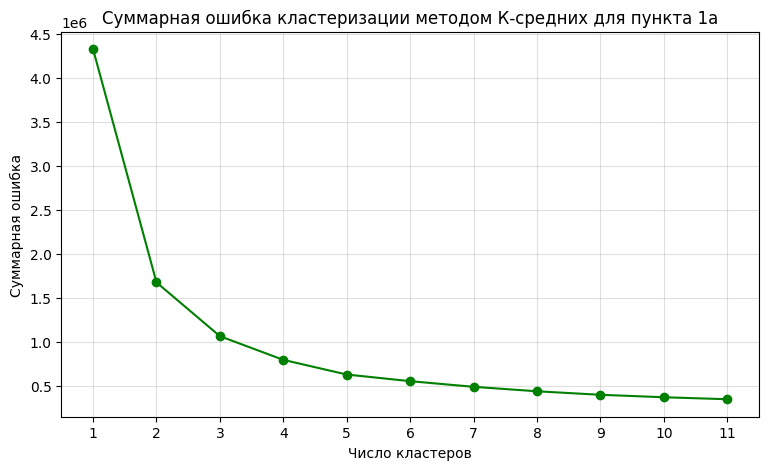

In [9]:
inert_1a = []
num_clust = np.arange(1, 12)

for i in num_clust:
    kmeans = KMeans(n_clusters = i, init = 'k-means++', n_init = 10, random_state = 42)
    kmeans.fit(data_1a)
    inert_1a.append(kmeans.inertia_)
    print(kmeans.inertia_)

plt.figure(figsize=(9,5))
plt.plot(list(num_clust), inert_1a, marker = 'o', color = 'green')
plt.xticks(list(num_clust))
plt.title('Суммарная ошибка кластеризации методом К-средних для пункта 1а')
plt.xlabel('Число кластеров')
plt.ylabel('Суммарная ошибка')
plt.grid(alpha = 0.4)
plt.show()

По виду полученного графика суммарной ошибки было выбрано число кластеров, равное 3.

In [10]:
X_1a = data_1a.copy()
num_of_clust_1a = 3
km_1a = KMeans(n_clusters=3, init = 'k-means++', n_init = 10, random_state=42)
km_1a.fit(X_1a)

data_1a['Cluster'] = km_1a.labels_

print('Число кластеров:', num_of_clust_1a)
print('Получены кластеры со следующими размерами:')
for cluster_number in range(num_of_clust_1a):
    print(f"    Кластер {cluster_number}: {(km_1a.labels_ == cluster_number).sum()} наблюдений")
print("Суммарная ошибка составляет:", km_1a.inertia_)

Число кластеров: 3
Получены кластеры со следующими размерами:
    Кластер 0: 1791 наблюдений
    Кластер 1: 1578 наблюдений
    Кластер 2: 1150 наблюдений
Суммарная ошибка составляет: 1064761.090188688


Визуализируем полученные кластеры:

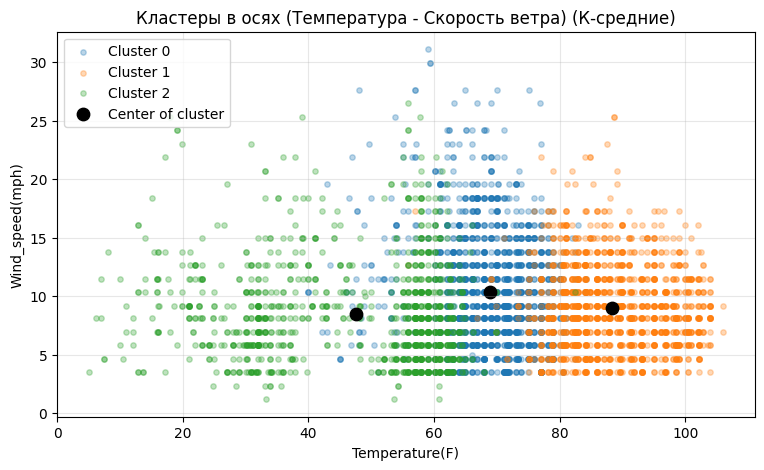

In [11]:
plt.figure(figsize = (9,5))
for c in range(num_of_clust_1a):
    sub = data_1a[data_1a['Cluster'] == c]
    plt.scatter(sub['Temperature(F)'], sub['Wind_Speed(mph)'], alpha=0.3, s = 15, label=f'Cluster {c}')

center = data_1a.groupby('Cluster')[['Temperature(F)', 'Wind_Speed(mph)']].mean()
plt.scatter(center['Temperature(F)'], center['Wind_Speed(mph)'], s = 80, color = 'black', label = 'Center of cluster')
plt.xlabel('Temperature(F)')
plt.ylabel('Wind_speed(mph)')
plt.title("Кластеры в осях (Температура - Скорость ветра) (К-средние)")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

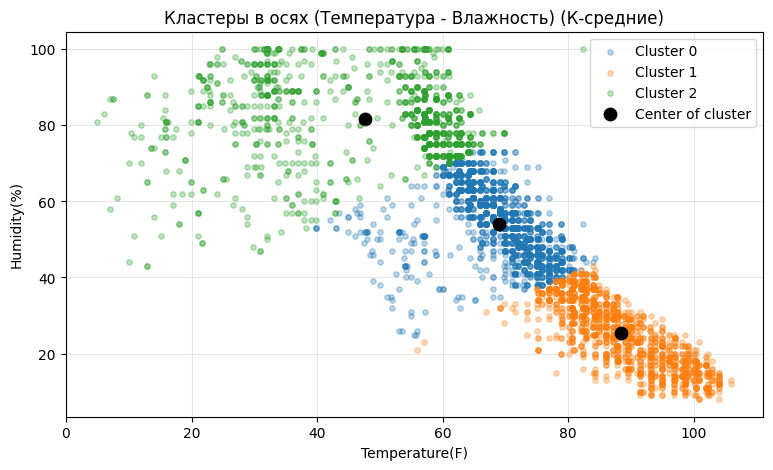

In [12]:
plt.figure(figsize = (9,5))
for c in range(num_of_clust_1a):
    sub = data_1a[data_1a['Cluster'] == c]
    plt.scatter(sub['Temperature(F)'], sub['Humidity(%)'], alpha=0.3, s = 15, label=f'Cluster {c}')

center = data_1a.groupby('Cluster')[['Temperature(F)', 'Humidity(%)']].mean()
plt.scatter(center['Temperature(F)'], center['Humidity(%)'], s = 80, color = 'black', label = 'Center of cluster')
plt.xlabel('Temperature(F)')
plt.ylabel('Humidity(%)')
plt.title("Кластеры в осях (Температура - Влажность) (К-средние)")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

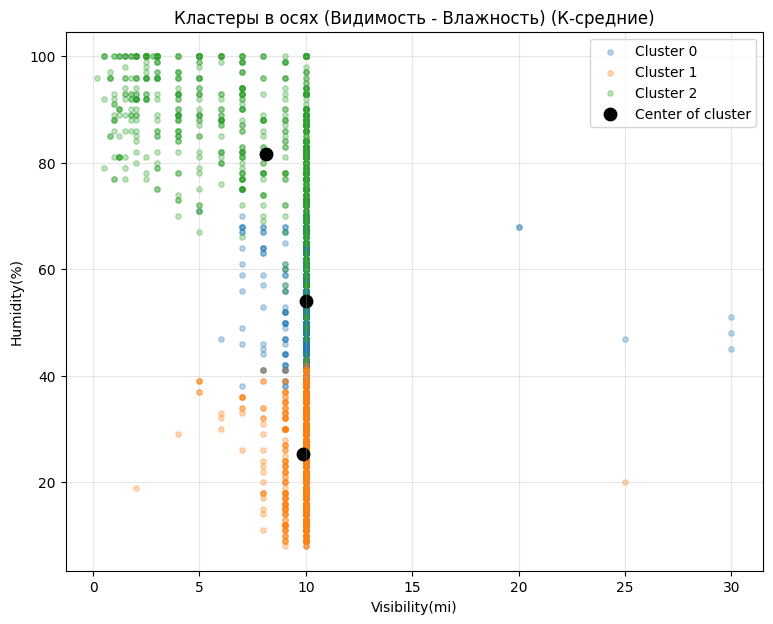

In [13]:
plt.figure(figsize = (9,7))
for c in range(num_of_clust_1a):
    sub = data_1a[data_1a['Cluster'] == c]
    plt.scatter(sub['Visibility(mi)'], sub['Humidity(%)'], alpha=0.3, s = 15, label=f'Cluster {c}')

center = data_1a.groupby('Cluster')[['Visibility(mi)', 'Humidity(%)']].mean()
plt.scatter(center['Visibility(mi)'], center['Humidity(%)'], s = 80, color = 'black', label = 'Center of cluster')
plt.xlabel('Visibility(mi)')
plt.ylabel('Humidity(%)')
plt.title("Кластеры в осях (Видимость - Влажность) (К-средние)")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

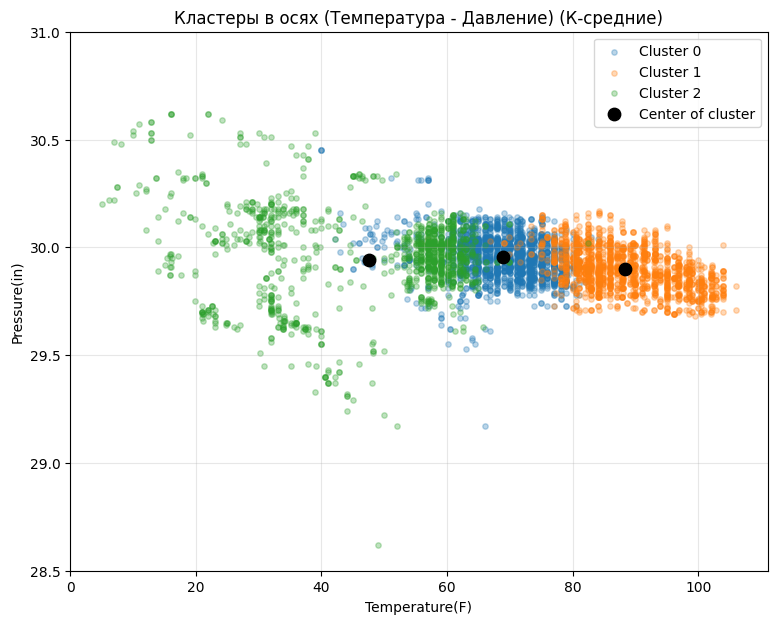

In [14]:
plt.figure(figsize = (9,7))
for c in range(num_of_clust_1a):
    sub = data_1a[data_1a['Cluster'] == c]
    plt.scatter(sub['Temperature(F)'], sub['Pressure(in)'], alpha=0.3, s = 15, label=f'Cluster {c}')

center = data_1a.groupby('Cluster')[['Temperature(F)', 'Pressure(in)']].mean()
plt.scatter(center['Temperature(F)'], center['Pressure(in)'], s = 80, color = 'black', label = 'Center of cluster')
plt.xlabel('Temperature(F)')
plt.ylabel('Pressure(in)')
plt.ylim(28.5, 31)
plt.title("Кластеры в осях (Температура - Давление) (К-средние)")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

Выведем профили кластеров, то есть средние значения каждого признака внутри кластера:

In [15]:
profile_1a = data_1a.groupby('Cluster').mean()
print(profile_1a.round(3))


         Severity  Temperature(F)  Wind_Chill(F)  Humidity(%)  Pressure(in)  \
Cluster                                                                       
0           2.467          68.939         25.318       53.996        29.956   
1           2.383          88.385         25.200       25.313        29.898   
2           2.406          47.556         24.284       81.690        29.942   

         Visibility(mi)  Wind_Direction  Wind_Speed(mph)  Precipitation(in)  
Cluster                                                                      
0                 9.983          10.475           10.379              0.000  
1                 9.868          11.075            9.007              0.000  
2                 8.125           9.719            8.455              0.003  


По полученным профилям, а также по диаграммам ранее можно сделать следующие выводы о кластерах:
- кластер 0 содержит в себе 1791 наблюдение, по профилю можно сказать, что в этот кластер попали случаи аварии с умеренной температурой (около 21 $\degree$ C), средней влажностью (54%); то есть можно назвать кластер как "Аварии в умеренную погоду".
- кластер 1 содержит в себе 1578 наблюдений; по профилю видно, что здесь - высокая температура воздуха (31 $\degree$ C), низкая влажность (25,31%). Можно назвать кластер как "Аварии в жаркую сухую погоду".
- кластер 2 содержит в себе 1150 наблюдений; низкая температура воздуха (около 8 $\degree$ C), высокая влажность (81,69%), худшая из представленных (однако вполне приемлимая) видимость около 8 миль. Можно назвать кластер "Аварии в холодную пасмурную погоду"
- класс серьезности аварий во всех трех кластерах примерно одинаков, что говорит о том, что погодные условия, хоть и разделили аварии на 3 кластера, не повлияли на степень серьезности аварии.
- суммарная ошибка кластеризации составила 1064761.09; при запуске метода К-средних (k = 1) суммарная ошибка составляла 4327325.94, то есть кластеризация корректна и показательна.

#### Пункт 1б

Копирование столбцов, необоходимых для выполнения этого пункта:

In [16]:
cols_1b = [
    'Severity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 
    'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 
    'Turning_Loop',
] 
data_1b = df[cols_1b].copy()
data_1b

,Severity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop
0,3,False,False,False,False,False,False,False,False,False,False,False,False
1,2,False,False,False,False,False,False,False,False,False,False,False,False
2,2,False,False,False,False,False,False,False,False,False,False,True,False
3,3,False,False,False,False,False,False,False,False,False,False,False,False
4,2,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,2,False,False,False,False,False,False,False,False,False,False,False,False
4996,2,False,True,False,False,False,False,False,False,False,False,True,False
4997,2,False,False,False,False,False,False,False,False,False,False,False,False
4998,2,False,False,False,False,False,False,False,False,False,False,False,False


Поиск пропущенных значений, а также вывод количества значений True в каждом из выделенных столбцов:

In [17]:
for col in cols_1b[1:]:
    data_1b[col] = data_1b[col].astype(int)

print('Обнаружено пропущенных значений:', int(data_1b.isna().sum().sum()))
print('Количество значений True в каждом из бинарных признаков: ')
print(data_1b[cols_1b[1:]].sum().to_string())
assert int(data_1b.isna().sum().sum()) == 0

Обнаружено пропущенных значений: 0
Количество значений True в каждом из бинарных признаков: 
Bump                 1
Crossing           278
Give_Way             6
Junction           633
No_Exit              6
Railway             44
Roundabout           1
Station             64
Stop               131
Traffic_Calming      2
Traffic_Signal     473
Turning_Loop         0


Можно обратить внимание, что признак `Turning_Loop` всегда содержит значение `False`, а значит не вносит различий между наблюдениями. Признаки `Bump`, `Give_way`, `No_Exit`, `Roundabout`, `Traffic_Calmig` встречаются весьма редко, от 1 до 6 раз.

Проводим кластеризацию методом К-средних; сначала определим оптимальное количество кластеров:

2723.109200000012
1466.062884705202
1047.435214391173
664.5229041437378
514.1300232799972
375.7486321745073
268.99878097683916
216.50650110978563
183.43695591194341


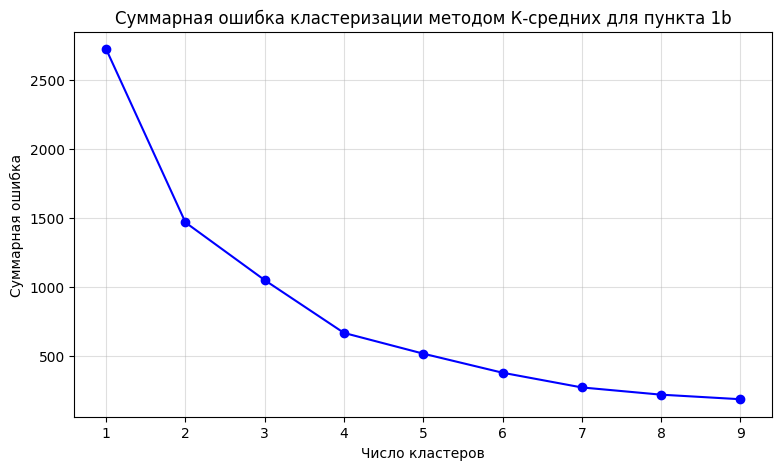

In [18]:
inert_1b = []
num_clust = np.arange(1, 10)

for i in num_clust:
    kmeans = KMeans(n_clusters = i, init = 'k-means++', n_init = 10, random_state = 42)
    kmeans.fit(data_1b)
    inert_1b.append(kmeans.inertia_)
    print(kmeans.inertia_)

plt.figure(figsize=(9,5))
plt.plot(list(num_clust), inert_1b, marker = 'o', color = 'blue')
plt.xticks(list(num_clust))
plt.title('Суммарная ошибка кластеризации методом К-средних для пункта 1b')
plt.xlabel('Число кластеров')
plt.ylabel('Суммарная ошибка')
plt.grid(alpha = 0.4)
plt.show()

В качестве числа кластеров для дальнейшей кластеризации было выбрано 4 кластера.

In [19]:
X_1b = data_1b.copy()
num_of_clust_1b = 4
km_1b = KMeans(n_clusters = num_of_clust_1b, init = 'k-means++', n_init = 10, random_state=42)
km_1b.fit(X_1b)

data_1b['Cluster'] = km_1b.labels_

print('Число кластеров:', num_of_clust_1b)
print('Получены кластеры со следующими размерами:')
for cluster_number in range(num_of_clust_1b):
    print(f"    Кластер {cluster_number}: {(km_1b.labels_ == cluster_number).sum()} наблюдений")
print("Суммарная ошибка составляет:", km_1b.inertia_)

Число кластеров: 4
Получены кластеры со следующими размерами:
    Кластер 0: 632 наблюдений
    Кластер 1: 472 наблюдений
    Кластер 2: 2293 наблюдений
    Кластер 3: 1603 наблюдений
Суммарная ошибка составляет: 664.5229041437378


In [20]:
data_1b

,Severity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Cluster
0,3,0,0,0,0,0,0,0,0,0,0,0,0,3
1,2,0,0,0,0,0,0,0,0,0,0,0,0,2
2,2,0,0,0,0,0,0,0,0,0,0,1,0,1
3,3,0,0,0,0,0,0,0,0,0,0,0,0,3
4,2,0,0,0,0,0,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,2,0,0,0,0,0,0,0,0,0,0,0,0,2
4996,2,0,1,0,0,0,0,0,0,0,0,1,0,1
4997,2,0,0,0,0,0,0,0,0,0,0,0,0,2
4998,2,0,0,0,0,0,0,0,0,0,0,0,0,2


Покажем на примере, что визуализация приведет к неочевидным выводам, так как признаки являются бинарными:

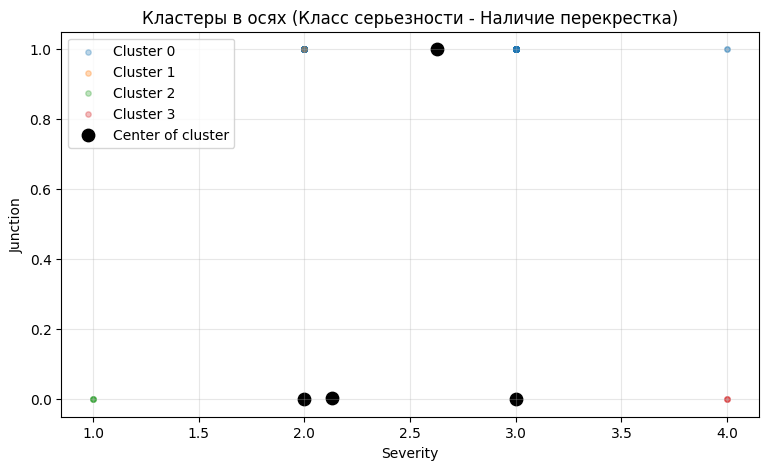

In [21]:
plt.figure(figsize = (9,5))
for c in range(num_of_clust_1b):
    sub = data_1b[data_1b['Cluster'] == c]
    plt.scatter(sub['Severity'], sub['Junction'], alpha=0.3, s = 15, label=f'Cluster {c}')

center = data_1b.groupby('Cluster')[['Severity', 'Junction']].mean()
plt.scatter(center['Severity'], center['Junction'], s = 80, color = 'black', label = 'Center of cluster')
plt.xlabel('Severity')
plt.ylabel('Junction')
plt.title("Кластеры в осях (Класс серьезности - Наличие перекрестка)")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

Поэтому сразу перейдем к расчету профиля кластеров:

In [22]:
profile_1b = data_1b.groupby('Cluster').mean()
print(profile_1b.round(3))


         Severity   Bump  Crossing  Give_Way  Junction  No_Exit  Railway  \
Cluster                                                                    
0           2.627  0.000     0.000     0.000     1.000    0.000    0.000   
1           2.129  0.000     0.388     0.006     0.002    0.000    0.013   
2           1.998  0.000     0.037     0.001     0.000    0.000    0.013   
3           3.002  0.001     0.006     0.000     0.000    0.004    0.005   

         Roundabout  Station   Stop  Traffic_Calming  Traffic_Signal  \
Cluster                                                                
0             0.002    0.002  0.002            0.000           0.002   
1             0.000    0.040  0.008            0.002           1.000   
2             0.000    0.014  0.053            0.000           0.000   
3             0.000    0.008  0.003            0.001           0.000   

         Turning_Loop  
Cluster                
0                 0.0  
1                 0.0  
2             

По профилям полученных кластеров можно сделать следующие выводы:
- Кластер 0, содержащий 632 наблюдения, характерен высоким значением признака `Junction` (узел дороги) и высоким значением `Severity`, то есть кластер содержит в себе достаточно серьезные аварии на нерегулируемых перекрестках;
- Кластер 1, содержит в себе 472 наблюдения, описывается высоким значением (по сравнению с другими кластерами) значением `Crossing` и высоким значением `Traffic_Signal`, а также значением `Severity`, близком к 2; таким образом, кластер можно назвать "Аварии на регулируемых перекрестках";
- кластер 2 (2293 наблюдения), самый крупный из полученных кластеров, характерен близком к 2 значением `Severity` и очень низкими значениями всех параметров. Предлагаемое название "Аварии низкой тяжести на обычных дорогах";
- кластер 3 (1603 наблюдения), ситуация почти аналогична кластеру 2, однако среднее значение признака `Severity` равно 3, что говорит о высокой тяжести аварий. "Тяжелые аварии на обычных дорогах"

Таким образом, можно сказать, что наличие дорожных параметров (светофоры, узлы дорог, перекрестки и так далее) заметно влияют на класс серьезности аварий.

#### Пункт 2a

In [23]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment

import seaborn as sns


Реализуем иерархическую кластеризацию на данных из пунктов 1а и 1b. Сначала построим дендрограмму, по которой определим число кластеров. Для этого копируются данные и рассчитывается матрица попарных расстояний с помощью функции `linkage`

In [24]:
X_2a = data_1a.drop(columns = 'Cluster').copy()
X_2a_2 = data_1a.drop(columns = 'Cluster').copy()
linked_1a_2 = linkage(X_2a, method='ward')
linked_1a = linkage(X_2a, method='ward')
linked_1a

array([[1.70000000e+01, 1.90000000e+01, 0.00000000e+00, 2.00000000e+00],
       [7.00000000e+00, 9.00000000e+00, 0.00000000e+00, 2.00000000e+00],
       [1.00000000e+01, 1.30000000e+01, 0.00000000e+00, 2.00000000e+00],
       ...,
       [9.03000000e+03, 9.03300000e+03, 8.80261778e+02, 1.95600000e+03],
       [9.02900000e+03, 9.03200000e+03, 9.90511354e+02, 2.56300000e+03],
       [9.03400000e+03, 9.03500000e+03, 2.27593166e+03, 4.51900000e+03]],
      shape=(4518, 4))

Построение дендрограммы, но так как полное дерево содержало бы 4518 листьев, то построим только последние 30 кластеров (в скобках подписаны размеры кластеров)

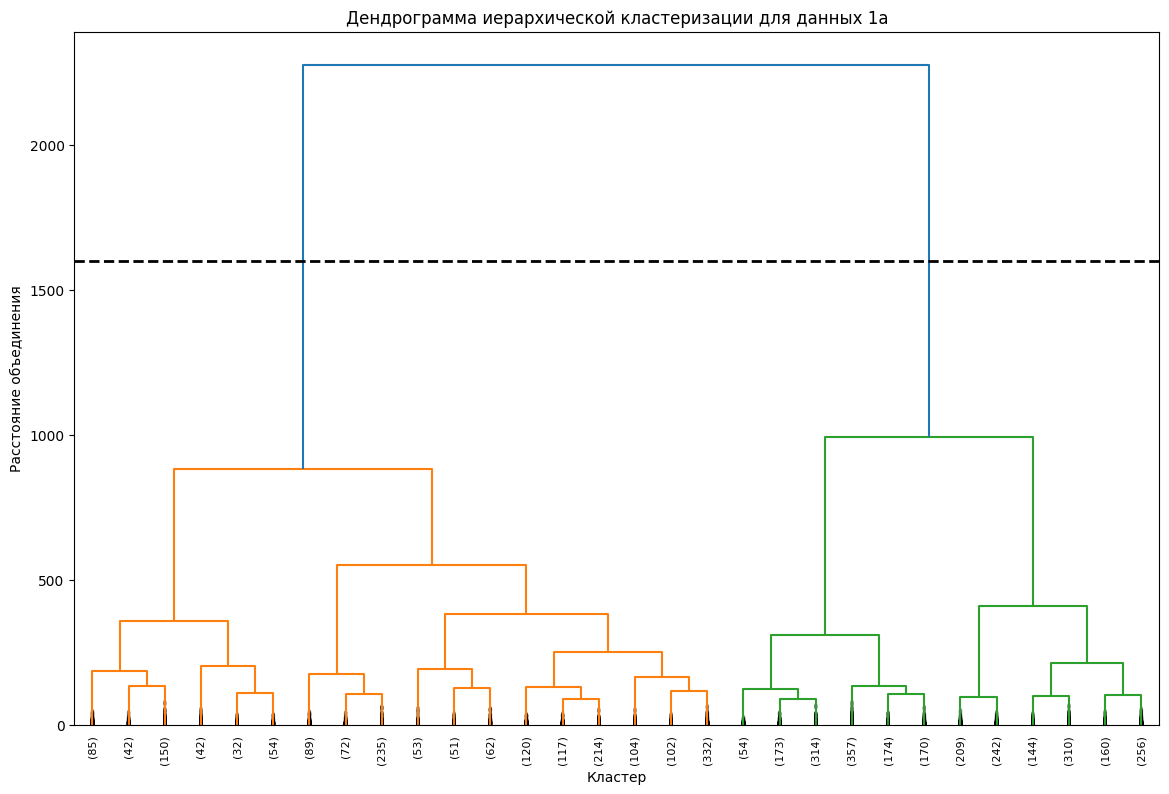

In [25]:
plt.figure(figsize=(14, 9))
plt.title('Дендрограмма иерархической кластеризации для данных 1а')
plt.xlabel('Кластер')
plt.ylabel('Расстояние объединения')

dendrogram(
    linked_1a,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True,
)

plt.axhline(y=1600, color='black', linestyle='--', linewidth=2)

plt.show()

Для определения оптимального числа кластеров находим максимальный промежуток на вертикальной оси без слияния, проводя горизонтальную черту. Было выбрано число кластеров, равное 2. Однако для сравнения ИКА с методом К-средних далее будет проведен иерархической кластеризацией на 3 кластера.

Проведедем иерархический кластерный анализ (ИКА) для 2 кластеров:

In [26]:
num_of_clust_2a = 2
hier_clust_2a = AgglomerativeClustering(n_clusters=num_of_clust_2a, metric='euclidean', linkage='ward')
labels_2a = hier_clust_2a.fit_predict(X_2a)

print('Размеры кластеров в ИКА в 2а:')
for c in range(num_of_clust_2a):
    print(f'  Кластер {c}: {(labels_2a == c).sum()} наблюдений')

Размеры кластеров в ИКА в 2а:
  Кластер 0: 2563 наблюдений
  Кластер 1: 1956 наблюдений


Рассмотрим профили кластеров:

In [27]:
profile_2a = (pd.DataFrame(X_2a).assign(Cluster=labels_2a).groupby('Cluster').mean().round(3))
print(profile_2a.to_string())

         Severity  Temperature(F)  Wind_Chill(F)  Humidity(%)  Pressure(in)  Visibility(mi)  Wind_Direction  Wind_Speed(mph)  Precipitation(in)
Cluster                                                                                                                                        
0           2.414          82.567         25.200       34.112        29.916           9.925          10.970            9.365              0.000
1           2.434          54.197         24.769       73.192        29.952           8.873           9.866            9.469              0.002


Полученные кластеры можно описать так:
- Кластер 0: "Аварии в жаркую, сухую погоду"
- Кластер 1: "Аварии в прохладную, влажную (пасмурную) погоду"

Визуализируем кластеры в тех же осях, что сделано ранее для пункта 1а.

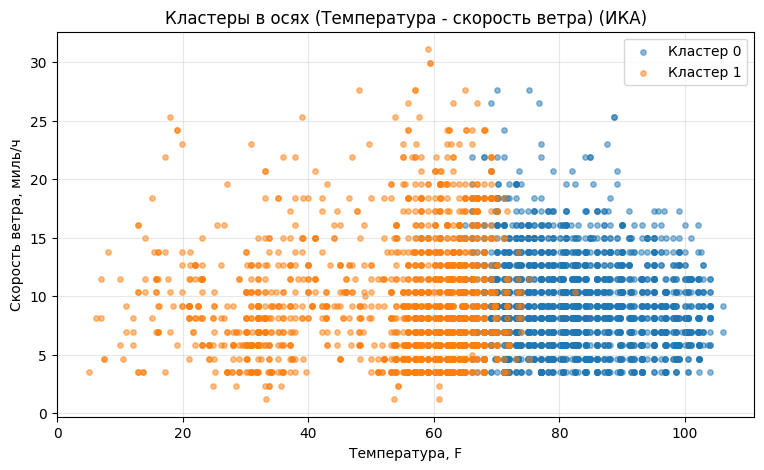

In [28]:
plt.figure(figsize=(9, 5))
for c in range(num_of_clust_2a):
    mask = labels_2a == c
    plt.scatter(X_2a.loc[mask, 'Temperature(F)'], X_2a.loc[mask, 'Wind_Speed(mph)'],
                alpha=0.5, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Скорость ветра, миль/ч')
plt.title('Кластеры в осях (Температура - скорость ветра) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


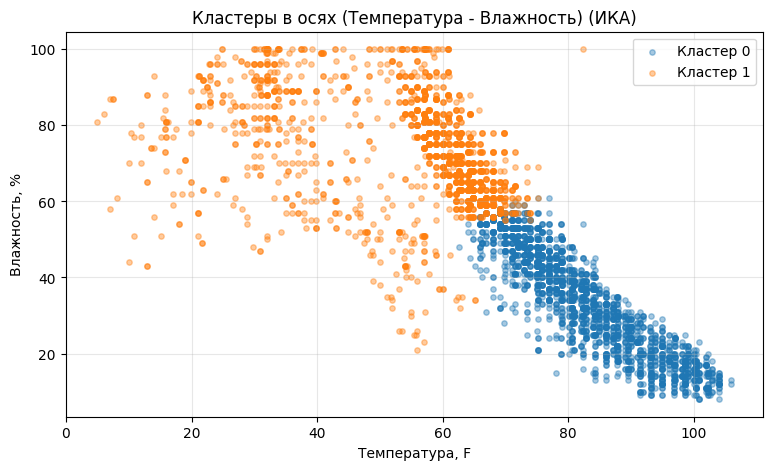

In [29]:
plt.figure(figsize=(9, 5))
for c in range(num_of_clust_2a):
    mask = labels_2a == c
    plt.scatter(X_2a.loc[mask, 'Temperature(F)'], X_2a.loc[mask, 'Humidity(%)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Влажность, %')
plt.title('Кластеры в осях (Температура - Влажность) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


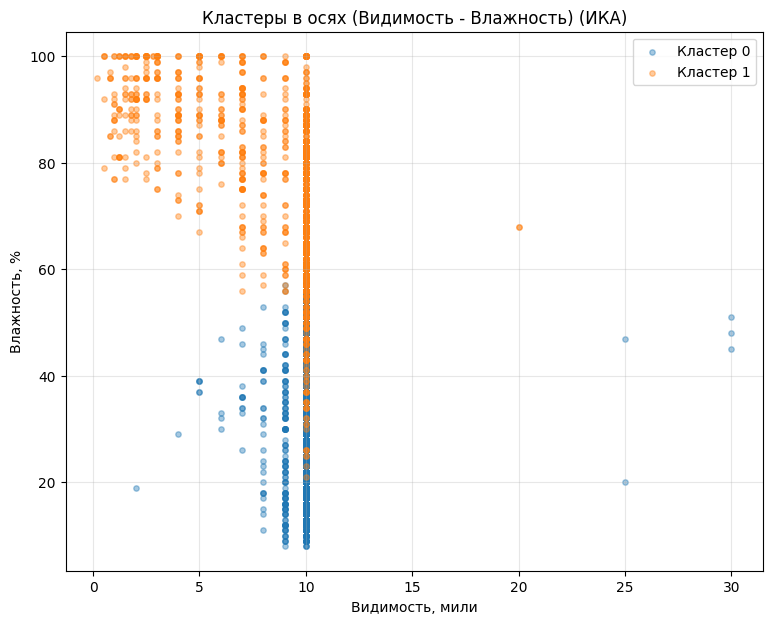

In [30]:
plt.figure(figsize=(9, 7))
for c in range(num_of_clust_2a):
    mask = labels_2a == c
    plt.scatter(X_2a.loc[mask, 'Visibility(mi)'], X_2a.loc[mask, 'Humidity(%)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Видимость, мили')
plt.ylabel('Влажность, %')
plt.title('Кластеры в осях (Видимость - Влажность) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

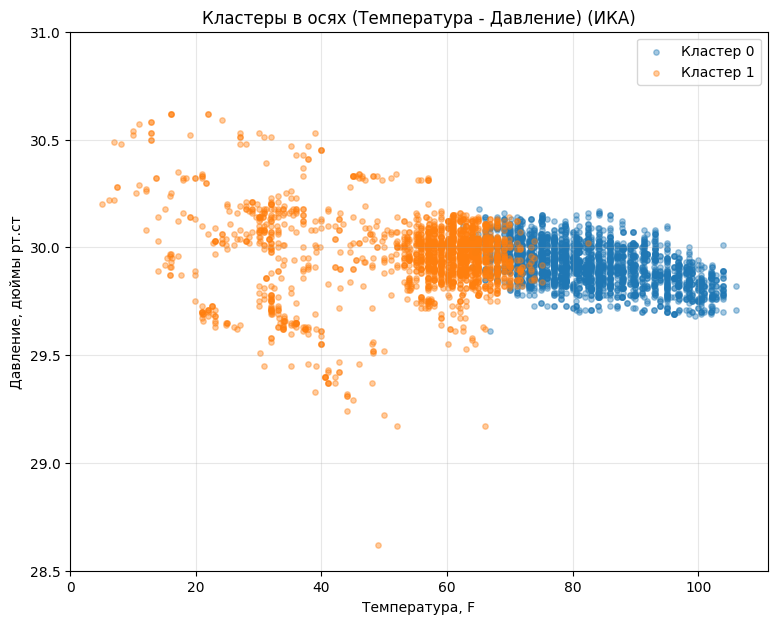

In [31]:
plt.figure(figsize=(9, 7))
for c in range(num_of_clust_2a):
    mask = labels_2a == c
    plt.scatter(X_2a.loc[mask, 'Temperature(F)'], X_2a.loc[mask, 'Pressure(in)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Давление, дюймы рт.ст')
plt.title('Кластеры в осях (Температура - Давление) (ИКА)')
plt.ylim(28.5, 31)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Проведем кластеризацию для 3 кластеров и сравним результат с методом К-средних:

In [32]:
num_of_clust_2a_2 = 3
hier_clust_2a_2 = AgglomerativeClustering(n_clusters=num_of_clust_2a_2, metric='euclidean', linkage='ward')
labels_2a_2 = hier_clust_2a_2.fit_predict(X_2a_2)

print('Размеры кластеров в ИКА в 2а:')
for c in range(num_of_clust_2a_2):
    print(f'  Кластер {c}: {(labels_2a_2 == c).sum()} наблюдений')

Размеры кластеров в ИКА в 2а:
  Кластер 0: 1956 наблюдений
  Кластер 1: 1321 наблюдений
  Кластер 2: 1242 наблюдений


In [33]:
profile_2a_2 = (pd.DataFrame(X_2a_2).assign(Cluster=labels_2a_2).groupby('Cluster').mean().round(3))
print(profile_2a_2.to_string())

         Severity  Temperature(F)  Wind_Chill(F)  Humidity(%)  Pressure(in)  Visibility(mi)  Wind_Direction  Wind_Speed(mph)  Precipitation(in)
Cluster                                                                                                                                        
0           2.434          54.197         24.769       73.192        29.952           8.873           9.866            9.469              0.002
1           2.381          90.081         25.200       23.006        29.893           9.874          11.230            9.108              0.000
2           2.449          74.575         25.200       45.925        29.942           9.980          10.693            9.639              0.000


Полученные кластеры можно описать так:
- Кластер 0: "Аварии в пасмурную погоду"
- Кластер 1: "Аварии жаркую сухую погоду"
- Кластер 2: "Аварии в обычную погоду"

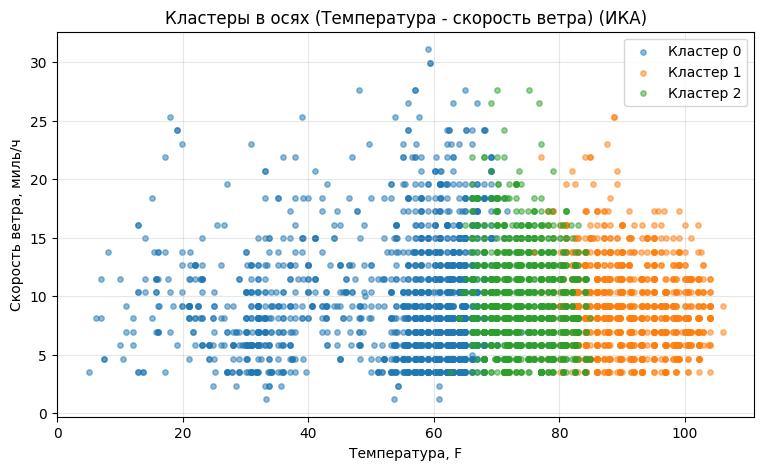

In [34]:
plt.figure(figsize=(9, 5))
for c in range(num_of_clust_2a_2):
    mask = labels_2a_2 == c
    plt.scatter(X_2a_2.loc[mask, 'Temperature(F)'], X_2a_2.loc[mask, 'Wind_Speed(mph)'],
                alpha=0.5, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Скорость ветра, миль/ч')
plt.title('Кластеры в осях (Температура - скорость ветра) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


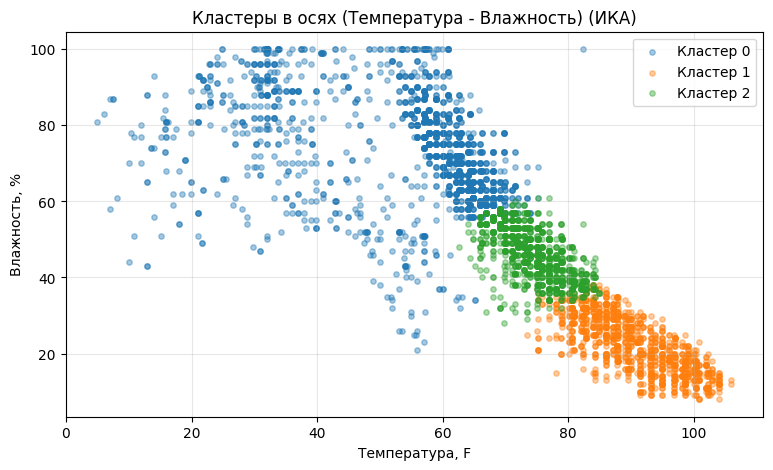

In [35]:
plt.figure(figsize=(9, 5))
for c in range(num_of_clust_2a_2):
    mask = labels_2a_2 == c
    plt.scatter(X_2a_2.loc[mask, 'Temperature(F)'], X_2a_2.loc[mask, 'Humidity(%)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Влажность, %')
plt.title('Кластеры в осях (Температура - Влажность) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


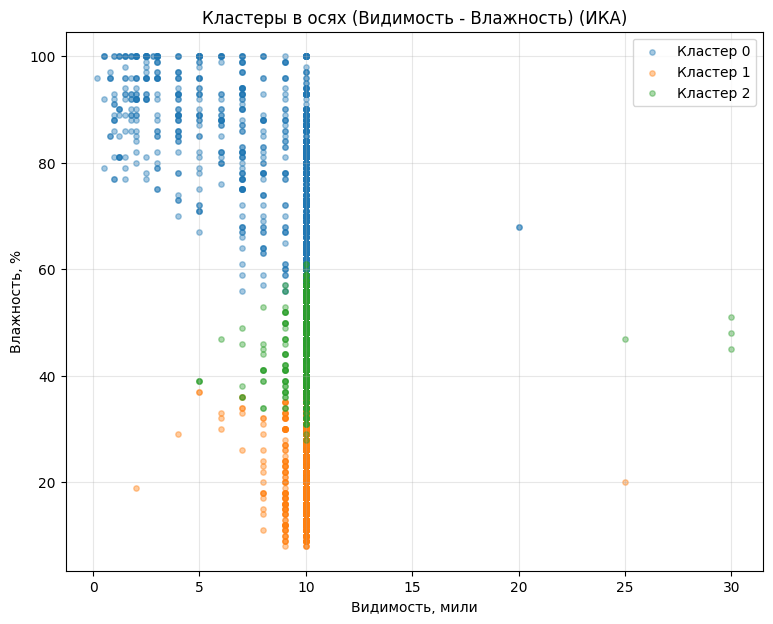

In [36]:
plt.figure(figsize=(9, 7))
for c in range(num_of_clust_2a_2):
    mask = labels_2a_2 == c
    plt.scatter(X_2a_2.loc[mask, 'Visibility(mi)'], X_2a_2.loc[mask, 'Humidity(%)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Видимость, мили')
plt.ylabel('Влажность, %')
plt.title('Кластеры в осях (Видимость - Влажность) (ИКА)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

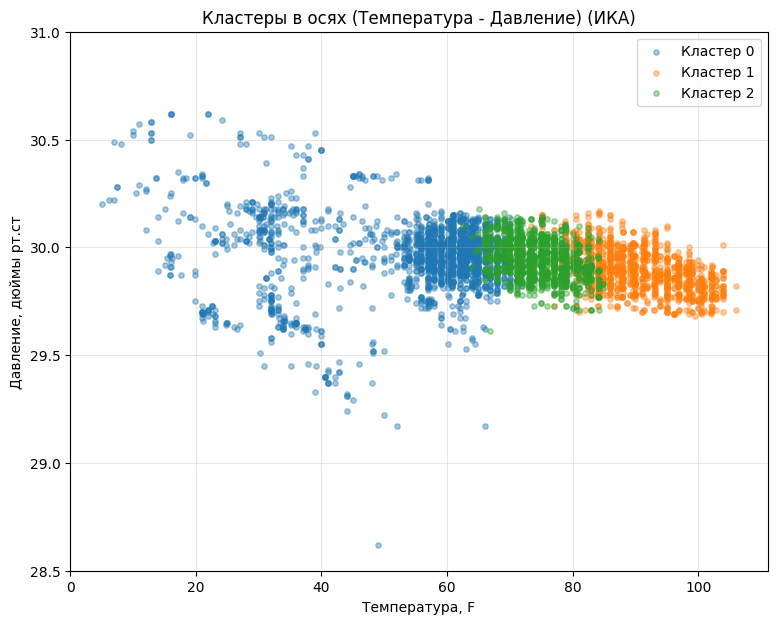

In [37]:
plt.figure(figsize=(9, 7))
for c in range(num_of_clust_2a_2):
    mask = labels_2a_2 == c
    plt.scatter(X_2a_2.loc[mask, 'Temperature(F)'], X_2a_2.loc[mask, 'Pressure(in)'],
                alpha=0.4, s=15, label=f'Кластер {c}')
plt.xlabel('Температура, F')
plt.ylabel('Давление, дюймы рт.ст')
plt.title('Кластеры в осях (Температура - Давление) (ИКА)')
plt.ylim(28.5, 31)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Сравнивая полученные диаграммы можно заметить различия на диаграммах №2 и №4. Таким образом, оба метода выделяют три примерно одинаковых по смыслу кластера (жаркая, обычная и пасмурная погода), однако полученные кластеры имеют разные центры.

#### Пункт 2б

Выполним аналогичные действия для данных из пункта 1б:

In [38]:
X_2b = data_1b.drop(columns = 'Cluster').copy()
linked_2b = linkage(X_2b, method='ward')
linked_2b

array([[0.00000000e+00, 3.00000000e+00, 0.00000000e+00, 2.00000000e+00],
       [1.00000000e+00, 6.00000000e+00, 0.00000000e+00, 2.00000000e+00],
       [2.00000000e+00, 4.00000000e+00, 0.00000000e+00, 2.00000000e+00],
       ...,
       [9.99300000e+03, 9.99400000e+03, 2.88115899e+01, 2.79900000e+03],
       [9.98300000e+03, 9.99500000e+03, 3.19954858e+01, 2.20100000e+03],
       [9.99600000e+03, 9.99700000e+03, 4.62342733e+01, 5.00000000e+03]],
      shape=(4999, 4))

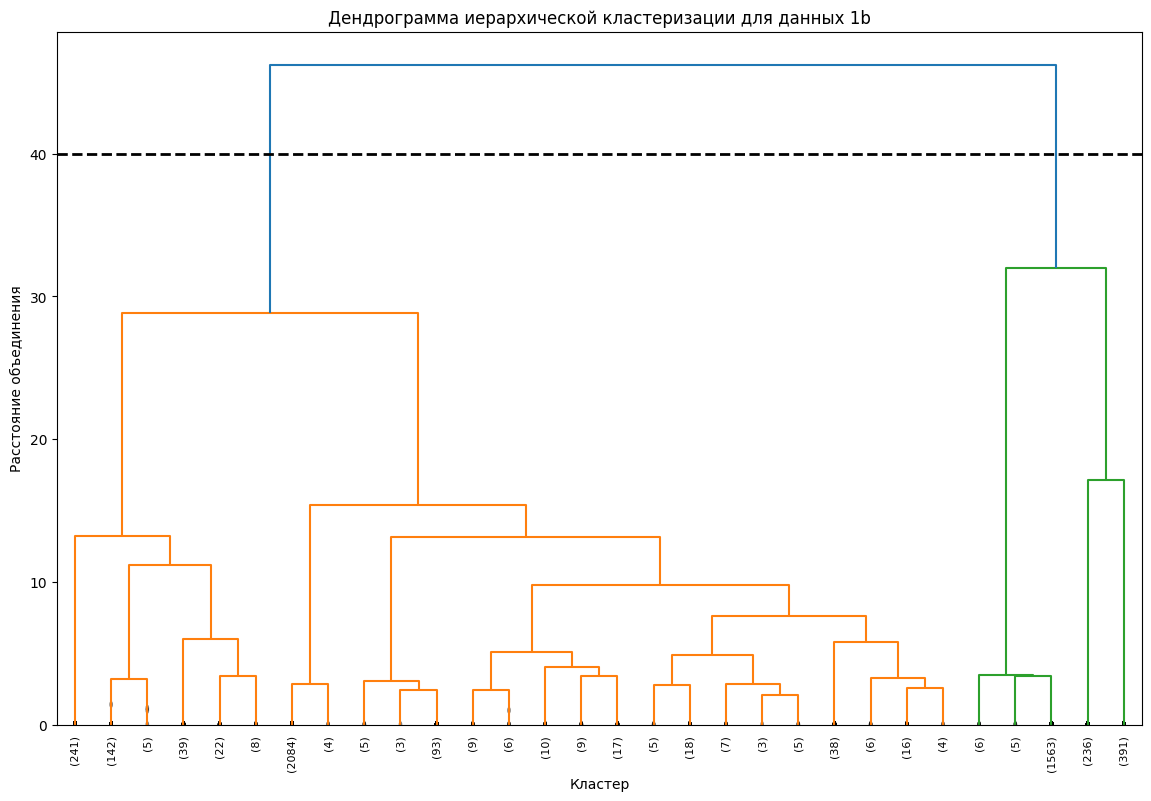

In [40]:
plt.figure(figsize=(14, 9))
plt.title('Дендрограмма иерархической кластеризации для данных 1b')
plt.xlabel('Кластер')
plt.ylabel('Расстояние объединения')

dendrogram(
    linked_2b,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True,
)

plt.axhline(y=40, color='black', linestyle='--', linewidth=2)

plt.show()

Было выбрано оптимальное число кластеров равное 2

In [41]:
num_of_clust_2b = 2
hier_clust_2b = AgglomerativeClustering(n_clusters=num_of_clust_2b, metric='euclidean', linkage='ward')
labels_2b = hier_clust_2b.fit_predict(X_2b)

print('Размеры кластеров в ИКА в 2а:')
for c in range(num_of_clust_2b):
    print(f'  Кластер {c}: {(labels_2b == c).sum()} наблюдений')

Размеры кластеров в ИКА в 2а:
  Кластер 0: 2201 наблюдений
  Кластер 1: 2799 наблюдений


Рассмотрим профили кластеров:

In [42]:
profile_2b = (pd.DataFrame(X_2b).assign(Cluster=labels_2b).groupby('Cluster').mean().round(3))
print(profile_2b.to_string())

         Severity  Bump  Crossing  Give_Way  Junction  No_Exit  Railway  Roundabout  Station   Stop  Traffic_Calming  Traffic_Signal  Turning_Loop
Cluster                                                                                                                                           
0           2.895   0.0     0.000     0.000     0.286    0.003    0.000         0.0    0.000  0.000              0.0           0.000           0.0
1           2.032   0.0     0.099     0.002     0.001    0.000    0.016         0.0    0.023  0.047              0.0           0.169           0.0


Полученные кластеры можно описать так:
- Кластер 0: "Тяжелые аварии на нерегулируемых перекрестках"
- Кластер 1: "Аварии на регулируемых перекрестках"

Таким образом, для данных 1а и 1б методом К-средних проведена кластеризация на 3 и 4 кластера соответственно; в то время как ИКА проведен на 2 кластера в обоих случаях. Можно сказать, что метод К-средних выполнил кластеризацию более детально, однако при равном количестве кластеров результаты работы методов практически совпадают.

Разница между методами очень заметна на полученных профилях кластеров в пунктах 1b и 2b; а также на визуализации кластеров для пунктов 1a и 2a.